# Credit Scoring Model: Predicting Loan Default
**CodeAlpha Machine Learning Internship, Task 1**

**Objective:** predict whether a borrower will default on a loan (`loan_status`: 1 = default, 0 = no default) using their financial history, so that lenders can judge creditworthiness.

**Approach:** exploratory data analysis, cleaning, feature engineering, then three classification models (Logistic Regression, Decision Tree, Random Forest) compared with Precision, Recall, F1-Score and ROC-AUC, validated with 5-fold stratified cross-validation.

**Dataset:** `crd.csv`, 32,581 loans and 12 columns (age, income, home ownership, employment length, loan intent, grade, amount, interest rate, loan-to-income ratio, previous default flag, credit history length).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

## 1. Load the Data
Load the CSV and check its shape, column names and data types.

In [2]:
df = pd.read_csv("crd.csv")
print("Shape:", df.shape)
df.head()
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape: (32581, 12)

Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Data types:
person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object


## 2. Exploratory Data Analysis (EDA)
First look at the quality of the data: missing values, duplicates and summary statistics, then the target variable.

**Findings:** `person_emp_length` (2.75%) and `loan_int_rate` (9.56%) have missing values, there are 165 duplicate rows, and the target is imbalanced (about 78% no default vs 22% default), so accuracy alone is a poor metric. We therefore focus on ROC-AUC, Precision and Recall.

In [3]:
print("Missing values:")
print(df.isnull().sum())

# Missing values percentage
missing_percent = df.isnull().mean() * 100
print("\nMissing percentage:")
print(missing_percent[missing_percent > 0].round(2))

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nNumerical summary:")
print(df.describe().T)

Missing values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Missing percentage:
person_emp_length    2.75
loan_int_rate        9.56
dtype: float64

Duplicate rows: 165

Numerical summary:
                              count          mean           std      min  \
person_age                  32581.0     27.734600      6.348078    20.00   
person_income               32581.0  66074.848470  61983.119168  4000.00   
person_emp_length           31686.0      4.789686      4.142630     0.00   
loan_amnt                   32581.0   9589.371106   6322.086646   500.00   
loan_int_rate               29465.0     11

In [4]:
# Count each loan status
print("Loan Status Counts:")
print(df["loan_status"].value_counts())

# Calculate percentages
print("\nLoan Status Percentages:")
print(
    (df["loan_status"].value_counts(normalize=True) * 100).round(2)
)

Loan Status Counts:
loan_status
0    25473
1     7108
Name: count, dtype: int64

Loan Status Percentages:
loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


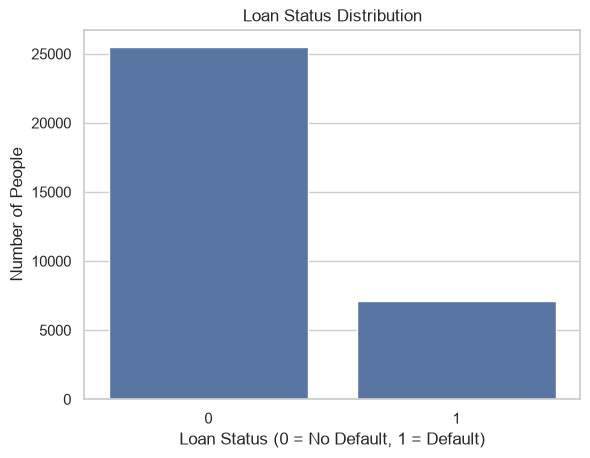

In [5]:
sns.countplot(data=df, x="loan_status")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of People")

plt.show()

**Default rate by home ownership:** renters (≈32%) default about four times more often than owners (≈7%). `OTHER` has only about 100 loans, so its rate is not reliable.

person_home_ownership
RENT        31.569987
OTHER       30.841121
MORTGAGE    12.570663
OWN          7.469040
Name: loan_status, dtype: float64


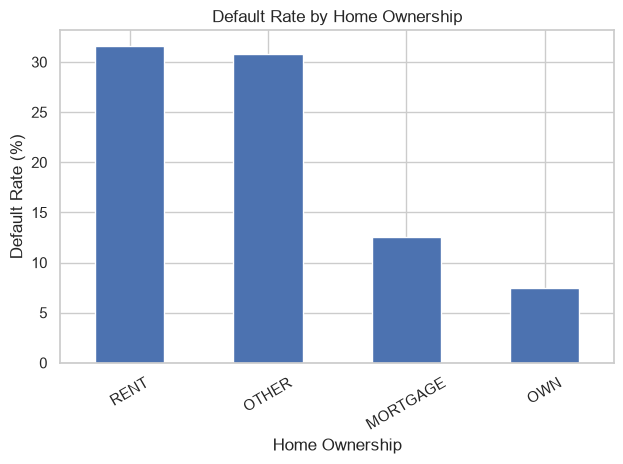

In [6]:
# Default rate by home ownership
ownership_rate = (
    df.groupby("person_home_ownership")["loan_status"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(ownership_rate)

ownership_rate.plot(kind="bar")
plt.title("Default Rate by Home Ownership")
plt.ylabel("Default Rate (%)")
plt.xlabel("Home Ownership")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Age check:** the maximum age is 144, which is impossible, so the data contains entry errors that we handle next.

In [7]:
# Statistical summary of age
print(df["person_age"].describe())

count    32581.000000
mean        27.734600
std          6.348078
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max        144.000000
Name: person_age, dtype: float64


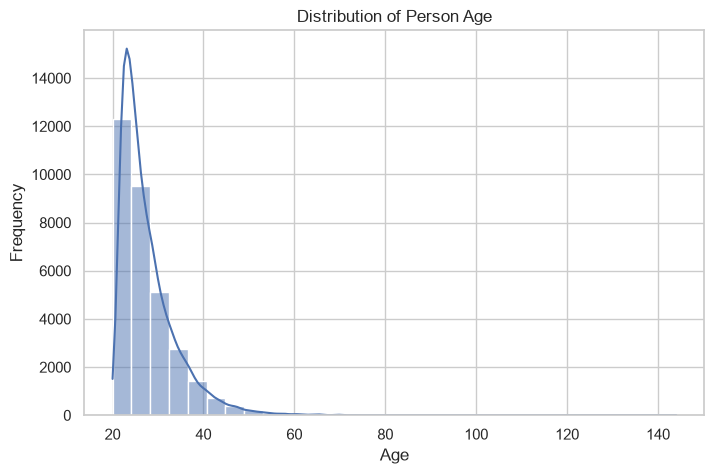

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="person_age", bins=30, kde=True)

plt.title("Distribution of Person Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

## 3. Data Cleaning
- Find impossible values (age above 100, employment length above 60 years or longer than the person's age): 7 rows.
- The extreme income of 6,000,000 belongs to the 144-year-old, so it disappears with the errors. The other high incomes (about 1.4M to 2M) belong to plausible people and are **kept**; the log transform will reduce their influence.
- Remove the 165 exact duplicates. Duplicates are removed **before** the split so the same row cannot appear in both train and test.

In [9]:
# Impossible rows (data entry errors)
errors = df[(df["person_age"] > 100) |
            (df["person_emp_length"] > 60) |
            (df["person_emp_length"] > df["person_age"])]
print(errors[["person_age", "person_emp_length", "person_income"]])


print(df["person_income"].describe(percentiles=[.5, .9, .99, .999]))
print("\nTop 5 income:")
print(df.nlargest(5, "person_income")[["person_age", "person_income", "loan_amnt", "loan_status"]])

       person_age  person_emp_length  person_income
0              22              123.0          59000
81            144                4.0         250000
183           144                4.0         200000
210            21              123.0         192000
575           123                2.0          80004
747           123                7.0          78000
32297         144               12.0        6000000
count    3.258100e+04
mean     6.607485e+04
std      6.198312e+04
min      4.000000e+03
50%      5.500000e+04
90%      1.100040e+05
99%      2.252000e+05
99.9%    6.480000e+05
max      6.000000e+06
Name: person_income, dtype: float64

Top 5 income:
       person_age  person_income  loan_amnt  loan_status
32297         144        6000000       5000            0
30049          42        2039784       8450            0
32546          60        1900000       1500            0
32497          63        1782000      12025            0
31924          44        1440000       6400       

In [10]:
print("Before:", df.shape)

df = df.drop_duplicates()
df = df.drop(errors.index.intersection(df.index))   
df = df.reset_index(drop=True)

print("After:", df.shape)   
print("Max age:", df["person_age"].max(), "| Max emp_length:", df["person_emp_length"].max())
print("Max income:", df["person_income"].max())

Before: (32581, 12)
After: (32409, 12)
Max age: 94 | Max emp_length: 41.0
Max income: 2039784


## 4. Univariate Analysis
Distribution of every feature. Skewness above 1 marks features that need a log transform.

**Findings:** `person_income` is extremely skewed (9.78); age, credit history length, employment length, loan amount and loan-to-income are moderately skewed; `loan_int_rate` is close to normal (0.21) but has two peaks that match the loan grades.

person_income                 9.78
person_age                    1.94
cb_person_cred_hist_length    1.66
person_emp_length             1.25
loan_amnt                     1.19
loan_percent_income           1.06
loan_int_rate                 0.21
dtype: float64


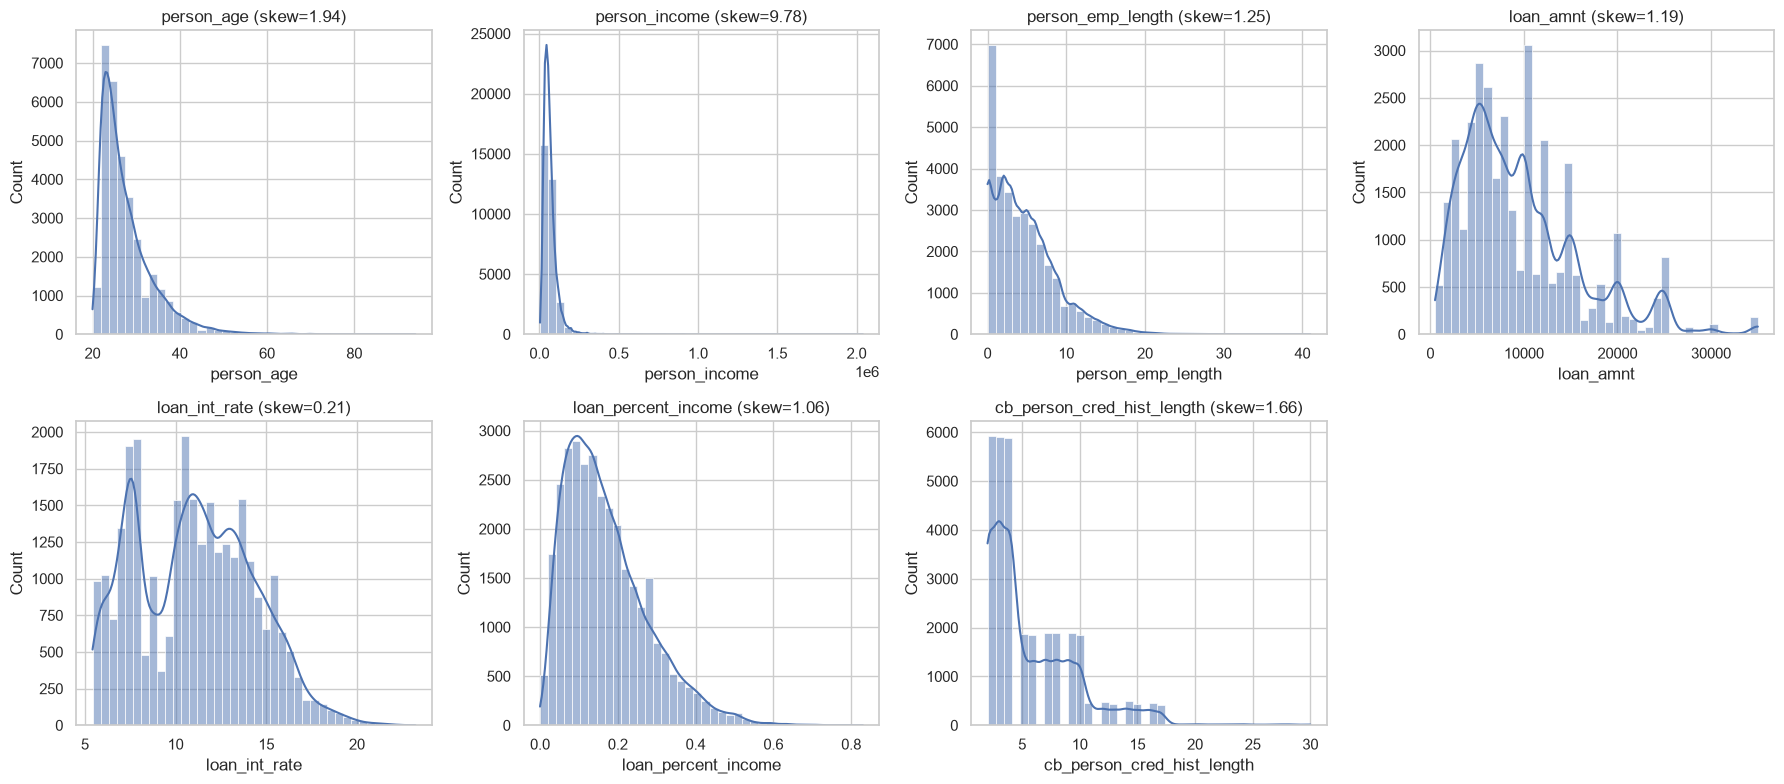

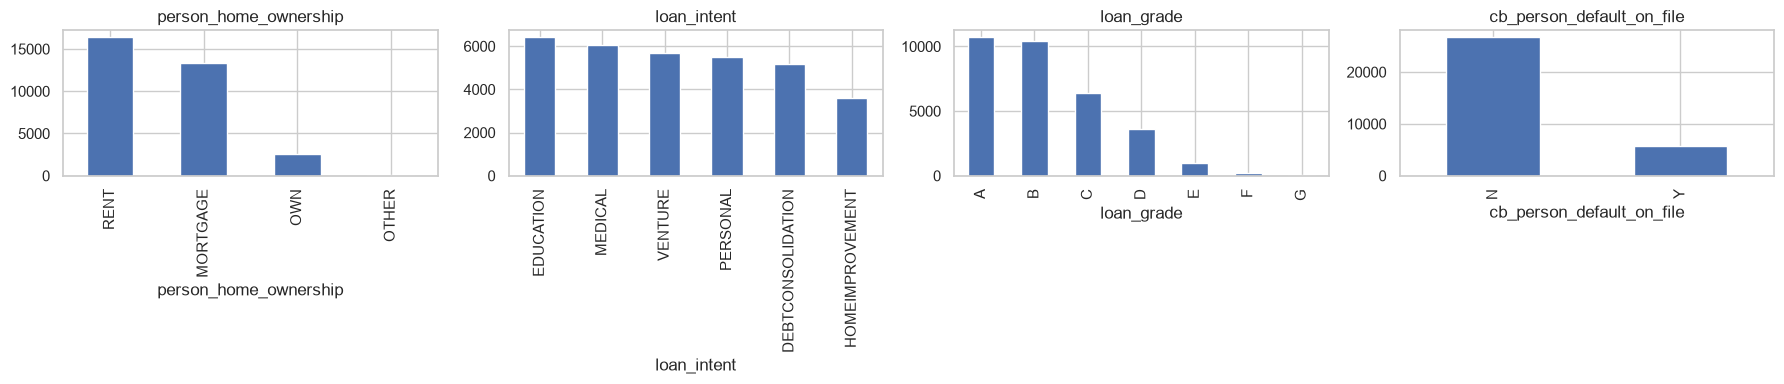

In [11]:
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]

# Skewness above 1 (or below -1) means a strongly skewed feature
print(df[num_cols].skew().round(2).sort_values(ascending=False))

# Histograms
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax)
    ax.set_title(f"{c} (skew={df[c].skew():.2f})")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

# Categorical
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, cat_cols):
    df[c].value_counts().plot(kind="bar", ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

## 5. Bivariate Analysis (feature vs default)
**Findings:**
- Defaulters have a higher interest rate, a higher loan-to-income ratio and a larger loan, and a lower income and shorter employment.
- Age and credit history length show almost no difference between the two groups.
- Default rate rises with the loan grade: A = 10%, B = 16%, C = 21%, then jumps to **59% at D** and reaches 98% at G.
- Interest rate rises with the grade, which explains the two peaks seen in the histogram.

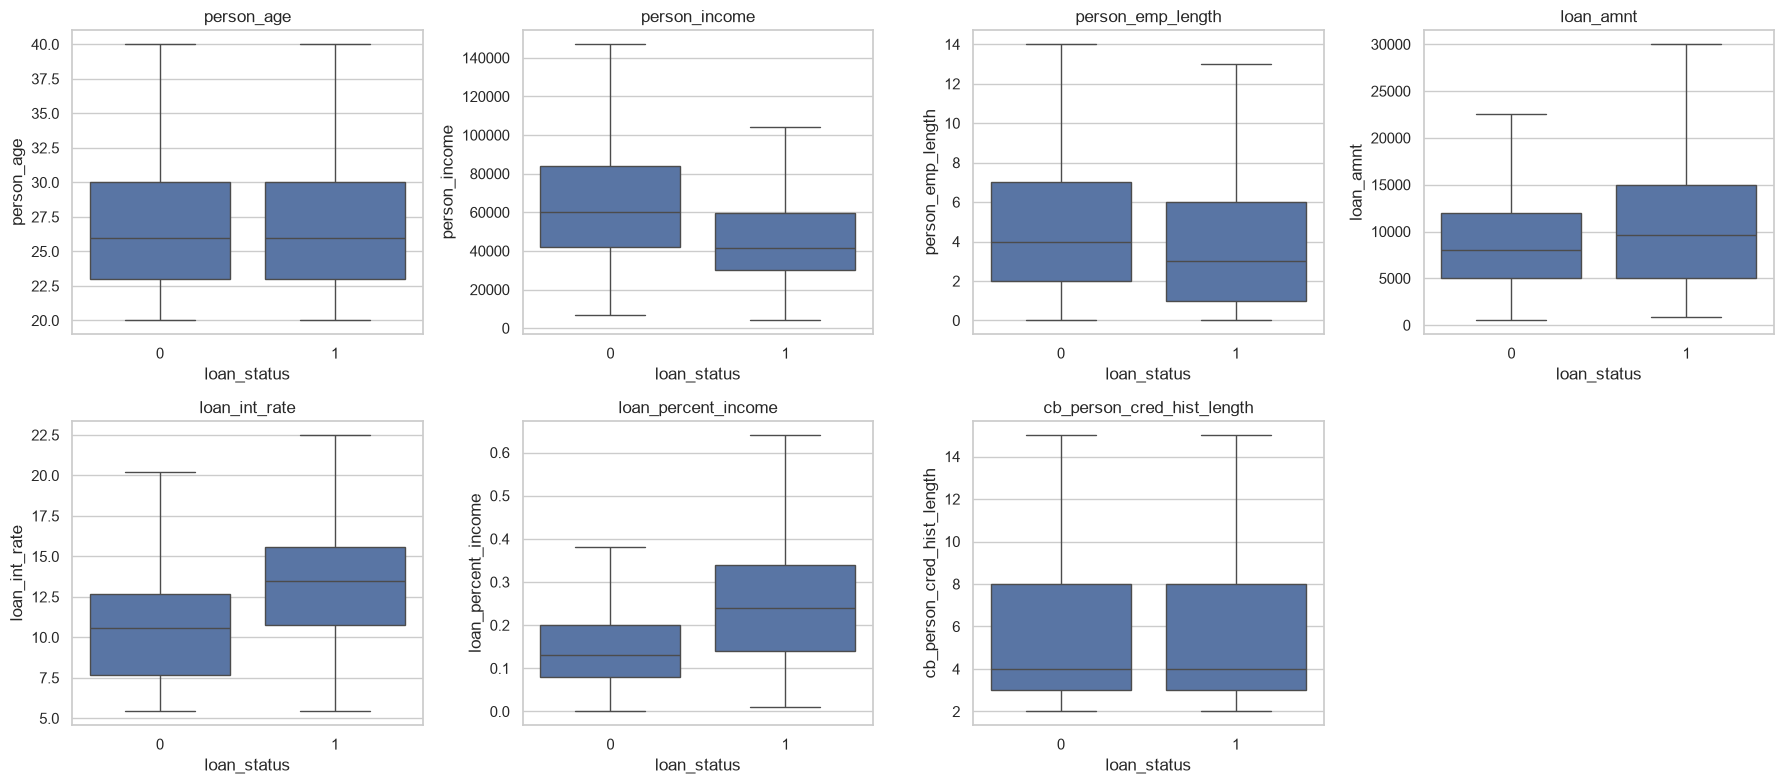

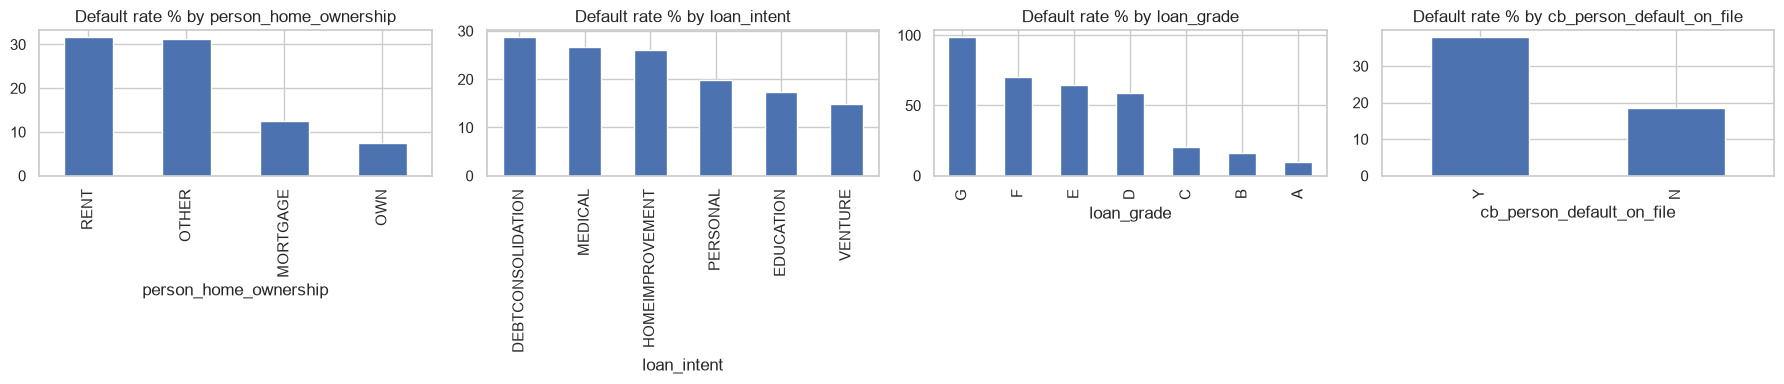

             mean    min    max
loan_grade                     
A            7.33   5.42   9.63
B           11.00   6.00  12.69
C           13.46   6.00  16.11
D           15.36   6.00  18.49
E           17.01   6.00  20.69
F           18.61  15.01  22.06
G           20.25  17.34  23.22
loan_grade
A    10.0
B    16.3
C    20.8
D    59.0
E    64.5
F    70.5
G    98.4
Name: loan_status, dtype: float64


In [12]:
# 1) Numeric features: defaulters (1) vs non-defaulters (0)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="loan_status", y=c, ax=ax, showfliers=False)
    ax.set_title(c)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

# 2) Categorical features: default rate (%) per category
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, cat_cols):
    (df.groupby(c)["loan_status"].mean().mul(100)
       .sort_values(ascending=False).plot(kind="bar", ax=ax))
    ax.set_title(f"Default rate % by {c}")
plt.tight_layout(); plt.show()

# 3) Check: loan grade vs interest rate and default rate
print(df.groupby("loan_grade")["loan_int_rate"].agg(["mean", "min", "max"]).round(2))
print(df.groupby("loan_grade")["loan_status"].mean().mul(100).round(1))

## 6. Correlation Analysis
Correlation of each feature with the target. The strongest are `loan_percent_income` (0.38), `loan_grade` (0.37) and `loan_int_rate` (0.34). `person_age` and `cb_person_cred_hist_length` are almost uncorrelated with default.

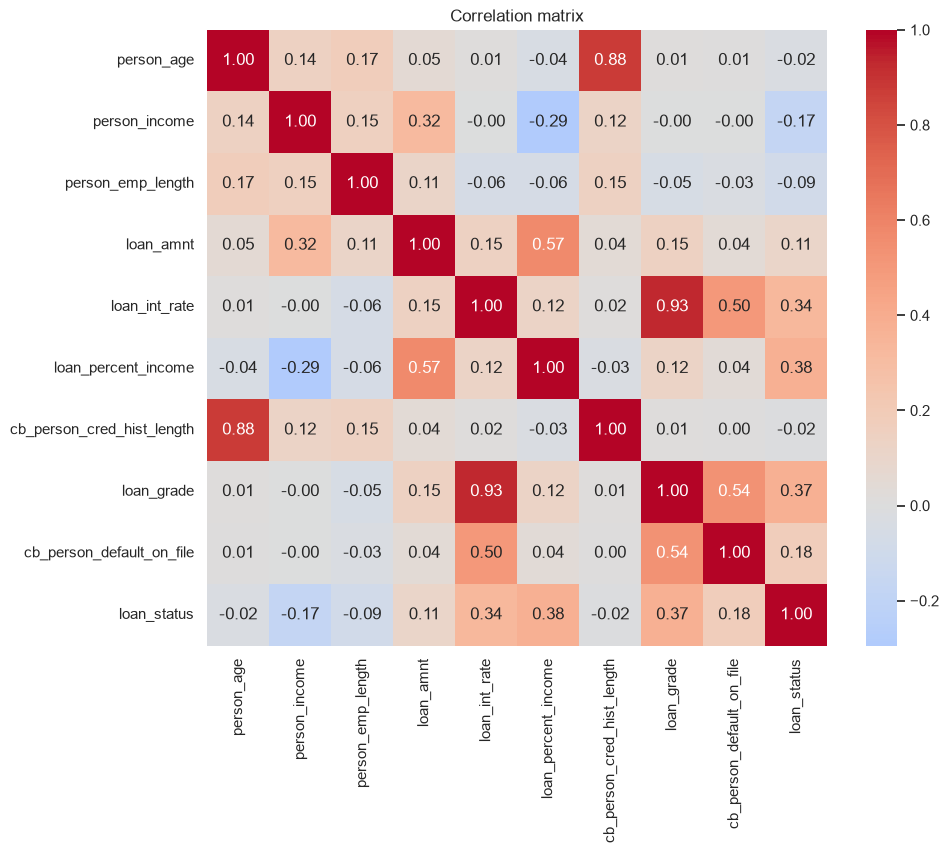

loan_percent_income           0.380
loan_grade                    0.373
loan_int_rate                 0.336
cb_person_default_on_file     0.179
loan_amnt                     0.106
cb_person_cred_hist_length   -0.016
person_age                   -0.022
person_emp_length            -0.086
person_income                -0.169
Name: loan_status, dtype: float64


In [13]:
# Temporary copy with simple encodings so correlation can be computed
tmp = df.copy()
tmp["loan_grade"] = tmp["loan_grade"].map({g: i for i, g in enumerate("ABCDEFG")})
tmp["cb_person_default_on_file"] = tmp["cb_person_default_on_file"].map({"Y": 1, "N": 0})

corr_cols = num_cols + ["loan_grade", "cb_person_default_on_file", "loan_status"]

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(tmp[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

# Correlation of each feature with the target only
print(tmp[corr_cols].corr()["loan_status"].drop("loan_status").sort_values(ascending=False).round(3))

In [14]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
1,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
2,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
3,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
4,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2


## 7. Feature Engineering
- `high_grade`: 1 when the grade is D or worse (the default rate jumps at D).
- Log transforms of the skewed features (`person_income`, `loan_amnt`, `person_emp_length`, `loan_percent_income`, `cb_person_cred_hist_length`).
- `grade_x_pct`: loan grade multiplied by loan-to-income ratio, which combines how risky the lender rates the loan with how heavy it is for the borrower.

In [15]:
# Binary flag: loan grade D or worse (default rate jumps from ~21% to ~59% at D)
df["high_grade"] = (df["loan_grade"].map({g: i for i, g in enumerate("ABCDEFG")}) >= 3).astype(int)

# Log transform for the heavily skewed features
for c in ["person_income", "loan_amnt", "person_emp_length", "loan_percent_income", "cb_person_cred_hist_length"]:
    df[c + "_log"] = np.log1p(df[c])

# Interaction: how burdensome the loan is, combined with how risky the lender rates it
df["grade_x_pct"] = df["loan_grade"].map({g: i for i, g in enumerate("ABCDEFG")}) * df["loan_percent_income"]

## 8. Encoding, Train/Test Split, Imputation and Scaling
The order matters to **avoid data leakage**:
1. **Encode** categorical features (ordinal for the grade, binary for the default flag, one-hot for home ownership and loan intent).
2. **Split** 80/20 with stratification, so both sets keep the 22% default rate.
3. **Impute** missing values with the **training** median only.
4. **Scale** numeric features with a scaler fitted on the **training** set only.

In [16]:
# ---------- 1) Encoding (safe before the split: no information from other rows is used) ----------
grade_map = {g: i for i, g in enumerate("ABCDEFG")}
df["loan_grade"] = df["loan_grade"].map(grade_map)                                   # ordinal: A=0 ... G=6
df["cb_person_default_on_file"] = df["cb_person_default_on_file"].map({"Y": 1, "N": 0})  # binary
df = pd.get_dummies(df, columns=["person_home_ownership", "loan_intent"], dtype=int)    # one-hot

# Rebuild the features that depend on loan_grade (it is numeric now)
df["high_grade"]  = (df["loan_grade"] >= 3).astype(int)
df["grade_x_pct"] = df["loan_grade"] * df["loan_percent_income"]

# The emp_length log still contains NaN, so drop it and recompute it after imputation
df = df.drop(columns=["person_emp_length_log"], errors="ignore")

# ---------- 2) Split FIRST (stratified, so both sets keep the ~22% default rate) ----------
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---------- 3) Impute missing values using the TRAIN median only (prevents leakage) ----------
for c in ["person_emp_length", "loan_int_rate"]:
    med = X_train[c].median()
    X_train[c] = X_train[c].fillna(med)
    X_test[c]  = X_test[c].fillna(med)

# Recompute the emp_length log now that there are no NaN values
X_train["person_emp_length_log"] = np.log1p(X_train["person_emp_length"])
X_test["person_emp_length_log"]  = np.log1p(X_test["person_emp_length"])

# ---------- 4) Scale numeric columns (fit on train only) ----------
numeric_cols = [
    "person_age", "person_income", "person_income_log",
    "person_emp_length", "person_emp_length_log",
    "loan_amnt", "loan_amnt_log", "loan_int_rate",
    "loan_percent_income", "loan_percent_income_log",
    "cb_person_cred_hist_length", "cb_person_cred_hist_length_log",
    "grade_x_pct",
]
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols]  = scaler.transform(X_test[numeric_cols])

# ---------- 5) Sanity checks ----------
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Nulls (train, test):", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())   # expect 0 0
print("Default rate train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))       # expect ~0.218 both

Train: (25927, 26) | Test: (6482, 26)
Nulls (train, test): 0 0
Default rate train/test: 0.2187 0.2188


In [17]:
X_train.isna().sum()

person_age                        0
person_income                     0
person_emp_length                 0
loan_grade                        0
loan_amnt                         0
loan_int_rate                     0
loan_percent_income               0
cb_person_default_on_file         0
cb_person_cred_hist_length        0
high_grade                        0
person_income_log                 0
loan_amnt_log                     0
loan_percent_income_log           0
cb_person_cred_hist_length_log    0
grade_x_pct                       0
person_home_ownership_MORTGAGE    0
person_home_ownership_OTHER       0
person_home_ownership_OWN         0
person_home_ownership_RENT        0
loan_intent_DEBTCONSOLIDATION     0
loan_intent_EDUCATION             0
loan_intent_HOMEIMPROVEMENT       0
loan_intent_MEDICAL               0
loan_intent_PERSONAL              0
loan_intent_VENTURE               0
person_emp_length_log             0
dtype: int64

## 9. Model Training and Cross-Validation
Three classifiers (the ones required by the task), all with `class_weight="balanced"` to handle the imbalance. Each is evaluated with **5-fold stratified cross-validation** on the training set (mean ± standard deviation), then checked once on the untouched test set.

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score

# The three models required by the task
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                                                  class_weight="balanced", random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                       class_weight="balanced", random_state=42, n_jobs=-1)
}

# 5-fold stratified cross-validation (each fold keeps the ~22% default rate)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = {}
for name, model in models.items():
    # 1) Cross-validation on the TRAIN set
    cvr = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["roc_auc", "precision", "recall", "f1"])
    rows[name] = {m: f"{cvr['test_' + m].mean():.3f} ± {cvr['test_' + m].std():.3f}"
                  for m in ["roc_auc", "precision", "recall", "f1"]}

    # 2) Final check on the untouched TEST set
    model.fit(X_train, y_train)
    rows[name]["test_roc_auc"] = round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3)

display(pd.DataFrame(rows).T)

,roc_auc,precision,recall,f1,test_roc_auc
Logistic Regression,0.885 ± 0.004,0.560 ± 0.009,0.801 ± 0.009,0.659 ± 0.009,0.885
Decision Tree,0.911 ± 0.001,0.831 ± 0.030,0.735 ± 0.007,0.780 ± 0.012,0.911
Random Forest,0.930 ± 0.003,0.851 ± 0.016,0.753 ± 0.003,0.799 ± 0.007,0.935


### Overfitting Check: Train vs Test
A large gap between the training score and the test score means the model memorised the training data. We compare the ROC-AUC on both sets for every model. The Random Forest is limited with `max_depth=12` and `min_samples_leaf=5`, because an unrestricted forest reaches a training ROC-AUC of 1.00 against 0.94 on the test set.

In [19]:
# Overfitting check: ROC-AUC on the training set vs the test set (models are already fitted)
gap = pd.DataFrame({
    name: {
        "Train ROC-AUC": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
        "Test ROC-AUC":  roc_auc_score(y_test,  m.predict_proba(X_test)[:, 1]),
    }
    for name, m in models.items()
}).T
gap["Gap"] = gap["Train ROC-AUC"] - gap["Test ROC-AUC"]
display(gap.round(3))

,Train ROC-AUC,Test ROC-AUC,Gap
Logistic Regression,0.886,0.885,0.001
Decision Tree,0.921,0.911,0.010
Random Forest,0.969,0.935,0.034


## 10. Final Evaluation of the Best Model
Random Forest has the best ROC-AUC, so we look at it in detail: classification report, confusion matrix, ROC curves of all models and the most important features.

              precision    recall  f1-score   support

  No Default       0.94      0.96      0.95      5064
     Default       0.86      0.77      0.81      1418

    accuracy                           0.92      6482
   macro avg       0.90      0.87      0.88      6482
weighted avg       0.92      0.92      0.92      6482



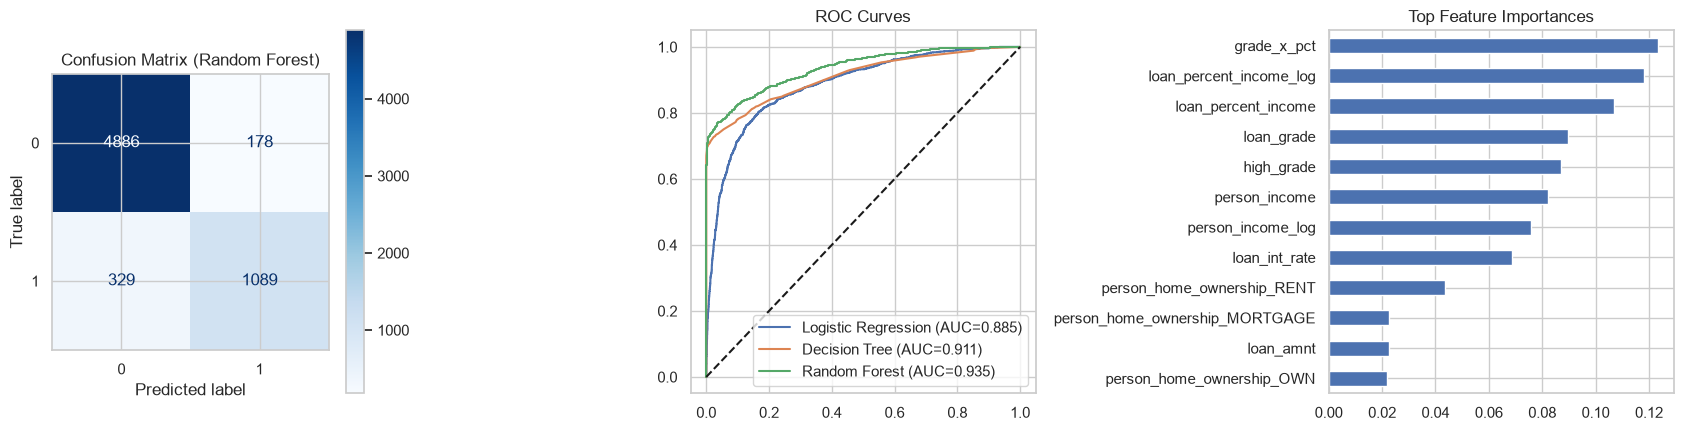

In [20]:
from sklearn.metrics import roc_curve

best = models["Random Forest"]                 # already fitted on X_train in the previous cell
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(classification_report(y_test, pred, target_names=["No Default", "Default"]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[0], cmap="Blues")
axes[0].set_title("Confusion Matrix (Random Forest)")

for name, m in models.items():                 # ROC curves of all three models
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curves"); axes[1].legend()

pd.Series(best.feature_importances_, index=X_train.columns).sort_values().tail(12) \
  .plot(kind="barh", ax=axes[2], title="Top Feature Importances")
plt.tight_layout(); plt.show()

## Conclusion
- **Random Forest is the best model**: CV ROC-AUC 0.930 ± 0.003, test ROC-AUC 0.935, default precision about 0.86, recall about 0.77 and F1 about 0.81.
- Decision Tree (depth limited to 8) reaches ROC-AUC 0.911, and Logistic Regression 0.885 with the highest recall (about 0.80) but low precision (about 0.56).
- Cross-validation scores are stable (standard deviation below 0.005) and close to the test scores.
- **Overfitting check:** the train-vs-test ROC-AUC gap is 0.001 for Logistic Regression, 0.010 for the Decision Tree and 0.034 for the Random Forest. The forest was limited with `max_depth=12` and `min_samples_leaf=5`; an unrestricted forest reaches a train ROC-AUC of 1.00 against 0.94 on test, so the limit trades a little test score (0.940 to 0.935) for a much smaller gap.
- The most important features are the engineered `grade_x_pct`, the loan-to-income ratio, the loan grade and income (several appear twice because of the log versions), so the engineered feature turned out to be the top predictor.
- Outlier removal (IQR or 99th percentile) was tested on income and interest rate and did not improve ROC-AUC, so only impossible values were removed.

**Possible improvements:** tune the decision threshold to trade precision for recall, try gradient boosting (XGBoost or LightGBM), and wrap the preprocessing in a `Pipeline` so it is also applied inside each cross-validation fold.